# 9주차 내 이미지 분류기 만들기 — 3교시 실습 프로젝트 〔정답본 · 교수용〕

**목표**: 내 이미지 데이터로 ① **CNN 을 처음부터** 학습시키고 ② **사전학습 ResNet18 을 빌려(전이학습)** 학습시킨 뒤,
③ **학습 곡선·혼동행렬·비교표**로 두 방식을 평가한다.

```
  1단계 데이터 불러오기 + 증강          ← 2교시 "데이터 증강"
  2단계 내 CNN 만들기                   ← 2교시 "Conv → BN → ReLU → Pool"
  3단계 학습 + 가장 좋은 모델 저장       ← 1교시 "Adam · 과적합 · 모델 저장"
  4단계 전이학습 (ResNet18 빌려 쓰기)    ← 2교시 "전이학습 · 백본 고정"
  5단계 평가 (혼동행렬 · 비교표)         ← 1교시 "평가지표"
  6단계 내 사진 한 장 예측해 보기
  도전  전체 미세조정 (선택)
```

### 빈칸 채우는 법

- 코드 안의 **`____`** 를 지우고 알맞은 코드를 적습니다. `____` 한 줄 = 코드 한 줄입니다.
- 빈칸 바로 위의 **`# 빈칸 ⓝ` 힌트**를 먼저 읽으세요.
- 셀을 실행한 뒤 **아래 "기대 출력"과 비교**합니다. 비슷하면 통과입니다.
- 빈칸은 모두 **10곳 · 17줄**입니다.

> **본인 데이터(`mydata/`)로 하면 숫자가 아래 기대 출력과 다릅니다.** 정상입니다.
> 기대 출력은 연습용 데이터(`mydata_sample/` — 비행기·자동차·고양이)로 실행한 값입니다.

> ⚠️ **이 파일은 교수용 정답본입니다.** 학생에게는 `14_image_project_blank.ipynb` 를 배포하세요.

---

## 0. 준비 — 라이브러리와 장치

In [1]:
# 셀 0 — 준비  (빈칸 없음)
import os, json, time, random
import torch, torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import models
from torchvision.datasets import ImageFolder
from torchvision.transforms import v2
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"     # 그래프 한글
plt.rcParams["axes.unicode_minus"] = False

def set_seed(s=42):                               # 어느 PC 에서나 같은 결과가 나오게
    random.seed(s); torch.manual_seed(s)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("장치 :", device)
os.makedirs("models", exist_ok=True)
os.makedirs("results", exist_ok=True)

장치 : cpu


---

## 1단계 — 데이터 불러오기 + 증강

`ImageFolder` 는 **폴더 이름을 정답(클래스)으로** 씁니다.

```
mydata/
├── train/   고양이/ 강아지/ 토끼/      ← 학습용
└── val/     고양이/ 강아지/ 토끼/      ← 검증용 (학습에 쓰지 않는다)
```

**데이터 증강**: 훈련 사진을 매번 **조금씩 다르게(잘라서·뒤집어서)** 보여 줍니다.
사진 수를 늘린 효과가 나서 **과적합이 줄어듭니다.** 검증 사진은 **증강하지 않습니다** — 시험 문제는 그대로 두어야 공정하니까요.

In [2]:
# 셀 1 — 데이터 불러오기
DATA = "mydata"                                   # ★ 내 데이터 폴더
if not os.path.isdir(DATA):                       # 없으면 연습용 데이터를 만든다
    from sample_data import make_sample
    DATA = make_sample()

IMG = 128                                         # 사진 크기 (가로·세로 128)
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)   # ImageNet 표준값

train_tf = v2.Compose([
    # 빈칸 ① (2줄) — 힌트 : 무작위로 잘라 IMG 크기로 맞추기 v2.RandomResizedCrop(IMG, scale=(0.8, 1.0)),
    #                       좌우로 무작위 뒤집기 v2.RandomHorizontalFlip(),
    v2.RandomResizedCrop(IMG, scale=(0.8, 1.0)),  # 사진 넓이의 80~100% 를 무작위로 잘라 IMG×IMG 로 맞춘다
    v2.RandomHorizontalFlip(),                    # 50% 확률로 좌우를 뒤집는다
    v2.ToImage(),                                 # PIL 사진 → 텐서 (3, IMG, IMG), 값은 0~255 정수
    v2.ToDtype(torch.float32, scale=True),        # 실수로 바꾸고 255 로 나눠 0~1 로 만든다
    v2.Normalize(MEAN, STD),                      # 채널마다 (값 − 평균) ÷ 표준편차 → 대략 −2~2
])
val_tf = v2.Compose([                             # 검증은 증강 없이 크기만 맞춘다
    v2.Resize((IMG, IMG)),
    v2.ToImage(), v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(MEAN, STD),
])

train_set = ImageFolder(f"{DATA}/train", transform=train_tf)
val_set   = ImageFolder(f"{DATA}/val",   transform=val_tf)
CLASSES = train_set.classes
NUM_CLASSES = len(CLASSES)

train_loader = DataLoader(train_set, batch_size=16, shuffle=True)
val_loader   = DataLoader(val_set, batch_size=32)

print("데이터 폴더 :", DATA)
print("클래스      :", CLASSES)
print(f"사진 수     : 훈련 {len(train_set)}장 / 검증 {len(val_set)}장")
xb, yb = next(iter(train_loader))
print("배치 shape  :", tuple(xb.shape))

완료 : mydata_sample/  (비행기, 자동차, 고양이 · train 60장 / val 20장씩)
데이터 폴더 : mydata_sample
클래스      : ['고양이', '비행기', '자동차']
사진 수     : 훈련 180장 / 검증 60장
배치 shape  : (16, 3, 128, 128)


**기대 출력** (연습용 데이터)
```
완료 : mydata_sample/  (비행기, 자동차, 고양이 · train 60장 / val 20장씩)
데이터 폴더 : mydata_sample
클래스      : ['고양이', '비행기', '자동차']
사진 수     : 훈련 180장 / 검증 60장
배치 shape  : (16, 3, 128, 128)
```

> **확인**: 배치 shape 의 네 숫자는 **(사진 수, 색 채널, 세로, 가로)** 입니다. 컬러 사진이라 채널이 **3** 입니다.

> **막히면**
> | 증상 | 조치 |
> |---|---|
> | `FileNotFoundError` | 폴더 이름·위치 확인. 터미널에서 `python prepare_mydata.py` 실행 |
> | 클래스가 1개로 나온다 | `train/` 바로 아래에 사진을 넣었다. **클래스 폴더**를 만드세요 |
> | `____` 가 남아 있다는 오류 | 빈칸 ① 을 채우지 않았다 |

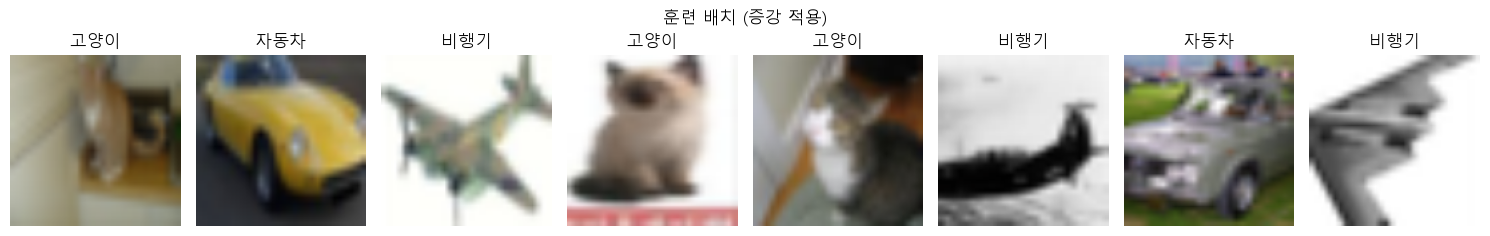

In [3]:
# 셀 2 — 증강된 훈련 사진 보기  (빈칸 없음)
def show(x):                                       # 정규화를 되돌려 화면용으로
    img = x.permute(1, 2, 0) * torch.tensor(STD) + torch.tensor(MEAN)
    return img.clamp(0, 1)

xs, ys = next(iter(train_loader))                  # 실행할 때마다 새 배치 — 섞어서 뽑고, 꺼낼 때 증강한다
fig, ax = plt.subplots(1, 8, figsize=(15, 2.4))
for i in range(8):
    ax[i].imshow(show(xs[i])); ax[i].set_title(CLASSES[ys[i]]); ax[i].axis("off")
plt.suptitle("훈련 배치 (증강 적용)"); plt.tight_layout(); plt.show()

> **관찰**: 셀 2 를 **여러 번 실행**해 보세요. 실행할 때마다 **다른 사진**이 뽑히고, **매번 다르게 잘리고 뒤집혀** 나옵니다. 이것이 증강입니다.

---

## 2단계 — 내 CNN 처음부터 만들기

2교시 판서의 **기본 블록**을 세 번 쌓습니다.

```
  입력 (3, 128, 128)
   → [블록1] Conv → BN → ReLU → Pool   (32, 64, 64)    ← Pool 이 가로·세로를 절반으로
   → [블록2] Conv → BN → ReLU → Pool   (64, 32, 32)
   → [블록3] Conv → BN → ReLU → Pool   (128, 16, 16)
   → 평균 풀링 (128 개 숫자로 요약) → Dropout → Linear → 클래스 점수
```

**평균 풀링 `nn.AdaptiveAvgPool2d(1)`** — 무늬 지도 한 장(16×16)을 **평균 숫자 하나**로 요약합니다. "이 무늬가 사진 전체에 평균 얼마나 있나"만 남기는 것입니다.
바로 `Flatten` 하면 숫자가 128×16×16 = **32,768개**라 Linear 파라미터가 98,307개지만, 평균 풀링을 거치면 **128개 · 387개**로 줄어듭니다.
**Adaptive** 는 출력 크기를 내가 정한다는 뜻 — `(1)` 이면 사진 크기와 상관없이 항상 1×1 입니다. 4단계의 ResNet18 도 끝에서 똑같이 해서 숫자 512개를 `fc` 에 넣습니다.

In [4]:
# 셀 3 — CNN 정의
def block(in_ch, out_ch):
    return nn.Sequential(
        # 빈칸 ② (4줄) — 힌트 : 2교시 기본 블록 순서 그대로
        #   nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),   ← 크기 유지
        #   nn.BatchNorm2d(out_ch),  nn.ReLU(),  nn.MaxPool2d(2)  ← 절반으로
        nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )

class MyCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128))
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),              # (128, 16, 16) → (128, 1, 1) : 채널마다 평균 하나
            nn.Flatten(),                         # → 128 개 숫자
            nn.Dropout(0.3),                      # 1교시 : 과적합 방지
            # 빈칸 ③ (1줄) — 힌트 : 들어오는 숫자 128 개 → 나가는 점수는 클래스 수(num_classes) 개
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

set_seed()
cnn = MyCNN(NUM_CLASSES).to(device)

# 가짜 사진 1장으로 shape 검산 — 학습 전에 항상
x = torch.randn(1, 3, IMG, IMG).to(device)
for i, b in enumerate(cnn.features, 1):
    x = b(x); print(f"블록{i} 후 :", tuple(x.shape))
print("최종 출력 :", tuple(cnn(torch.randn(1, 3, IMG, IMG).to(device)).shape))
print(f"파라미터 수 : {sum(p.numel() for p in cnn.parameters()):,}")

블록1 후 : (1, 32, 64, 64)
블록2 후 : (1, 64, 32, 32)
블록3 후 : (1, 128, 16, 16)
최종 출력 : (1, 3)
파라미터 수 : 94,083


**기대 출력**
```
블록1 후 : (1, 32, 64, 64)
블록2 후 : (1, 64, 32, 32)
블록3 후 : (1, 128, 16, 16)
최종 출력 : (1, 3)
파라미터 수 : 94,083
```

> **확인**: 블록을 지날 때마다 **채널은 늘고(32→64→128) 가로·세로는 절반(64→32→16)** 이 됩니다.
> 최종 출력의 두 번째 숫자가 **클래스 수**와 같으면 통과입니다.

> **막히면**
> | 증상 | 원인 |
> |---|---|
> | `Expected 3 channels` / `expected input[1, 3, ...]` | 첫 블록 `block(3, 32)` 의 3 을 바꿨다 |
> | `BatchNorm` 관련 오류 | `BatchNorm1d` 를 썼다. 이미지는 **`BatchNorm2d`** |
> | 최종 출력이 `(1, 128)` | 빈칸 ③ 의 Linear 를 빠뜨렸다 |

---

## 3단계 — 학습 함수 만들기 + 내 CNN 학습

학습 루프는 **5단계**입니다 (4·5주차와 같습니다).

```
  ① 예측  out = model(xb)        ② 손실  loss = loss_fn(out, yb)
  ③ 기울기 지우기  ④ 역전파  ⑤ 가중치 갱신
```

여기에 1교시에 배운 두 가지를 더합니다.
- **매 epoch 검증** → 훈련/검증 곡선을 그려 **과적합**을 확인
- **검증 정확도가 가장 좋았던 순간을 저장** (`state_dict`) → 마지막이 아니라 **최고**를 남긴다

In [5]:
# 셀 4 — 평가 함수와 학습 함수
loss_fn = nn.CrossEntropyLoss()

@torch.no_grad()
def evaluate(model, loader):
    model.eval()                                  # 평가 모드 (Dropout 끔)
    total_loss = correct = n = 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        total_loss += loss_fn(out, yb).item() * len(yb)
        correct += (out.argmax(1) == yb).sum().item()
        n += len(yb)
    return total_loss / n, correct / n


def fit(model, epochs, lr, save_path):
    set_seed()
    # 빈칸 ④ (1줄) — 힌트 : 1교시 "기본은 Adam".  torch.optim.Adam(모델의 파라미터, lr=lr)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "val_loss": [], "val_acc": []}
    best_acc, t0 = 0.0, time.time()

    for epoch in range(1, epochs + 1):
        model.train()                             # 학습 모드 (Dropout 켬)
        run, n = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)                       # ① 예측
            loss = loss_fn(out, yb)               # ② 손실
            # 빈칸 ⑤ (3줄) — 힌트 : ③ 기울기 지우기 → ④ 역전파 → ⑤ 갱신
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            run += loss.item() * len(yb); n += len(yb)

        val_loss, val_acc = evaluate(model, val_loader)
        hist["train_loss"].append(run / n)
        hist["val_loss"].append(val_loss)
        hist["val_acc"].append(val_acc)

        mark = ""
        if val_acc > best_acc:                    # 지금까지 중 최고면 저장
            best_acc = val_acc
            # 빈칸 ⑥ (1줄) — 힌트 : 가중치만 파일로.  torch.save(model.state_dict(), save_path)
            torch.save(model.state_dict(), save_path)
            mark = "  ← 최고, 저장"
        print(f"epoch {epoch:2d} | 훈련 손실 {run/n:.4f} | 검증 손실 {val_loss:.4f} "
              f"| 검증 정확도 {val_acc*100:5.1f}%{mark}")

    hist["best_acc"], hist["time"] = best_acc, time.time() - t0
    print(f"\n최고 검증 정확도 {best_acc*100:.1f}%  |  학습 시간 {hist['time']:.1f}초  |  저장 : {save_path}")
    return hist


def plot_history(hist, title):
    ep = range(1, len(hist["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    ax[0].plot(ep, hist["train_loss"], "o-", label="훈련 손실")
    ax[0].plot(ep, hist["val_loss"], "o-", label="검증 손실")
    ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].grid(alpha=.3); ax[0].set_title(f"{title} — 손실")
    ax[1].plot(ep, [a * 100 for a in hist["val_acc"]], "o-", color="tab:green")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("%"); ax[1].grid(alpha=.3); ax[1].set_title(f"{title} — 검증 정확도")
    plt.tight_layout(); plt.show()

import inspect                                    # 빈칸을 비워 두었는지 검사
if "____" in inspect.getsource(fit):
    print("⚠️ 빈칸 ④ ⑤ ⑥ 중 아직 채우지 않은 곳이 있습니다")
else:
    print("함수 준비 완료 : evaluate / fit / plot_history")

함수 준비 완료 : evaluate / fit / plot_history


> **이 셀은 함수를 만들기만 합니다.** `함수 준비 완료` 가 나오면 통과입니다. 학습은 다음 셀에서 합니다.

> **포인트**: `model.train()` 과 `model.eval()` — Dropout·BatchNorm 은 **학습할 때와 평가할 때 다르게** 동작합니다.
> 평가 전에 `eval()` 을 부르지 않으면 점수가 들쭉날쭉합니다.

epoch  1 | 훈련 손실 1.0213 | 검증 손실 0.9923 | 검증 정확도  50.0%  ← 최고, 저장


epoch  2 | 훈련 손실 0.9060 | 검증 손실 0.9008 | 검증 정확도  65.0%  ← 최고, 저장


epoch  3 | 훈련 손실 0.8620 | 검증 손실 0.8507 | 검증 정확도  60.0%


epoch  4 | 훈련 손실 0.7935 | 검증 손실 0.8190 | 검증 정확도  65.0%


epoch  5 | 훈련 손실 0.7826 | 검증 손실 0.8150 | 검증 정확도  68.3%  ← 최고, 저장


...

epoch 11 | 훈련 손실 0.7021 | 검증 손실 0.8001 | 검증 정확도  71.7%


epoch 12 | 훈련 손실 0.6683 | 검증 손실 0.8424 | 검증 정확도  61.7%


epoch 13 | 훈련 손실 0.6842 | 검증 손실 0.6989 | 검증 정확도  73.3%


epoch 14 | 훈련 손실 0.6750 | 검증 손실 0.6996 | 검증 정확도  76.7%  ← 최고, 저장


epoch 15 | 훈련 손실 0.6876 | 검증 손실 0.7416 | 검증 정확도  68.3%

최고 검증 정확도 76.7%  |  학습 시간 130.8초  |  저장 : models/my_cnn.pt


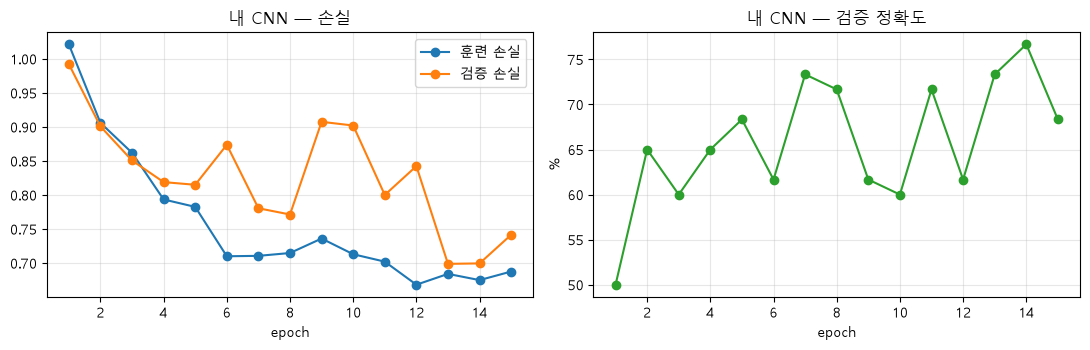

In [6]:
# 셀 5 — 내 CNN 학습  (빈칸 없음)
cnn_hist = fit(cnn, epochs=15, lr=1e-3, save_path="models/my_cnn.pt")
plot_history(cnn_hist, "내 CNN")

**기대 출력** (연습용 데이터 · 교수 PC 실측, 학습 130.8초)
```
epoch  1 | 훈련 손실 1.0213 | 검증 손실 0.9923 | 검증 정확도  50.0%  ← 최고, 저장
epoch  2 | 훈련 손실 0.9060 | 검증 손실 0.9008 | 검증 정확도  65.0%  ← 최고, 저장
epoch  3 | 훈련 손실 0.8620 | 검증 손실 0.8507 | 검증 정확도  60.0%
epoch  4 | 훈련 손실 0.7935 | 검증 손실 0.8190 | 검증 정확도  65.0%
epoch  5 | 훈련 손실 0.7826 | 검증 손실 0.8150 | 검증 정확도  68.3%  ← 최고, 저장
epoch  6 | 훈련 손실 0.7100 | 검증 손실 0.8738 | 검증 정확도  61.7%
epoch  7 | 훈련 손실 0.7106 | 검증 손실 0.7806 | 검증 정확도  73.3%  ← 최고, 저장
epoch  8 | 훈련 손실 0.7148 | 검증 손실 0.7714 | 검증 정확도  71.7%
epoch  9 | 훈련 손실 0.7361 | 검증 손실 0.9075 | 검증 정확도  61.7%
epoch 10 | 훈련 손실 0.7130 | 검증 손실 0.9021 | 검증 정확도  60.0%
epoch 11 | 훈련 손실 0.7021 | 검증 손실 0.8001 | 검증 정확도  71.7%
epoch 12 | 훈련 손실 0.6683 | 검증 손실 0.8424 | 검증 정확도  61.7%
epoch 13 | 훈련 손실 0.6842 | 검증 손실 0.6989 | 검증 정확도  73.3%
epoch 14 | 훈련 손실 0.6750 | 검증 손실 0.6996 | 검증 정확도  76.7%  ← 최고, 저장
epoch 15 | 훈련 손실 0.6876 | 검증 손실 0.7416 | 검증 정확도  68.3%

최고 검증 정확도 76.7%  |  학습 시간 130.8초  |  저장 : models/my_cnn.pt
```

> **관찰 ★ — 1교시 "과적합" 을 찾아보세요.**
> 증강과 드롭아웃을 넣었기 때문에 훈련 손실과 검증 손실이 크게 벌어지지는 않습니다(마지막 훈련 0.69 / 검증 0.74). 대신 **검증 정확도가 60~77% 사이를 크게 오르내립니다.** 마지막 epoch 은 68.3% 인데 최고는 epoch 14 의 **76.7%** 입니다 — **마지막이 아니라 최고를 저장해야 하는 이유**(1교시)가 바로 이것입니다. 검증 사진이 60장뿐이라 한 장 차이로 정확도가 1.7%p 씩 움직입니다.

> **막히면**: 손실이 전혀 안 내려가면 빈칸 ⑤ 의 **순서**(`zero_grad → backward → step`)를 확인하세요.

---

## 4단계 — 전이학습: 사전학습 ResNet18 빌려 쓰기

**ResNet18** 은 ImageNet(사진 약 120만 장 · 1,000 종류)으로 **이미 학습된** CNN 입니다.
선·모서리·질감·모양을 보는 눈이 이미 갖춰져 있습니다.

```
  [ResNet18]  사진 → [ 백본 : 특징을 뽑는 부분 ] → fc (1000 종류)   ← ImageNet 용 머리
                            │ 고정한다 (학습 안 함)        ✗ 떼어 낸다
                            └──────────────────→ 새 fc (내 클래스 수)  ★ 이것만 학습
```

- **백본 고정(동결, freeze)** : `requires_grad = False` → 기울기를 계산하지 않으므로 **바뀌지 않습니다.**
- **헤드 교체** : 마지막 층 `fc` 를 **내 클래스 수**에 맞는 새 `nn.Linear` 로 바꿉니다.

> 처음 실행하면 사전학습 가중치(약 45MB)를 인터넷에서 내려받습니다. 한 번 받으면 PC 에 저장되어 다음부터는 바로 불러옵니다. 다운로드 오류(`URLError`)가 나면 손을 들어 알려 주세요.

In [7]:
# 셀 6 — ResNet18 불러오기 · 고정 · 헤드 교체
set_seed()
# 빈칸 ⑦ (1줄) — 힌트 : 사전학습 가중치까지 함께.  models.resnet18(weights="DEFAULT")
resnet = models.resnet18(weights="DEFAULT")

# 빈칸 ⑧ (2줄) — 힌트 : resnet 의 모든 파라미터 resnet.parameters() 를 돌면서 requires_grad 를 False 로 (백본 고정)
for p in resnet.parameters():
    p.requires_grad = False

print("원래 머리 :", resnet.fc)
# 빈칸 ⑨ (1줄) — 힌트 : 입력 512 개 → 내 클래스 수 NUM_CLASSES.  nn.Linear(512, NUM_CLASSES)  (새 층은 학습 가능 상태로 시작한다)
resnet.fc = nn.Linear(512, NUM_CLASSES)
print("바꾼 머리 :", resnet.fc)
resnet = resnet.to(device)

trainable = sum(p.numel() for p in resnet.parameters() if p.requires_grad)
total     = sum(p.numel() for p in resnet.parameters())
print(f"\n학습하는 파라미터 {trainable:,} / 전체 {total:,}  ({trainable/total*100:.3f}%)")

원래 머리 : Linear(in_features=512, out_features=1000, bias=True)
바꾼 머리 : Linear(in_features=512, out_features=3, bias=True)

학습하는 파라미터 1,539 / 전체 11,178,051  (0.014%)


**기대 출력**
```
원래 머리 : Linear(in_features=512, out_features=1000, bias=True)
바꾼 머리 : Linear(in_features=512, out_features=3, bias=True)

학습하는 파라미터 1,539 / 전체 11,178,051  (0.014%)
```

> **확인 ★**: 전체 약 **1,100만 개** 중 학습하는 것은 **새 머리의 1,539개뿐**입니다.
> 내 CNN(94,083개)보다도 훨씬 적습니다. 그런데 결과는 어떨까요?

epoch  1 | 훈련 손실 1.1173 | 검증 손실 0.7098 | 검증 정확도  75.0%  ← 최고, 저장


epoch  2 | 훈련 손실 0.7263 | 검증 손실 0.5696 | 검증 정확도  86.7%  ← 최고, 저장


epoch  3 | 훈련 손실 0.5628 | 검증 손실 0.4896 | 검증 정확도  93.3%  ← 최고, 저장


epoch  4 | 훈련 손실 0.4977 | 검증 손실 0.4329 | 검증 정확도  90.0%


epoch  5 | 훈련 손실 0.4562 | 검증 손실 0.4240 | 검증 정확도  85.0%


epoch  6 | 훈련 손실 0.3993 | 검증 손실 0.3767 | 검증 정확도  91.7%


epoch  7 | 훈련 손실 0.3294 | 검증 손실 0.3578 | 검증 정확도  90.0%


epoch  8 | 훈련 손실 0.3504 | 검증 손실 0.3217 | 검증 정확도  93.3%

최고 검증 정확도 93.3%  |  학습 시간 59.7초  |  저장 : models/resnet_tl.pt


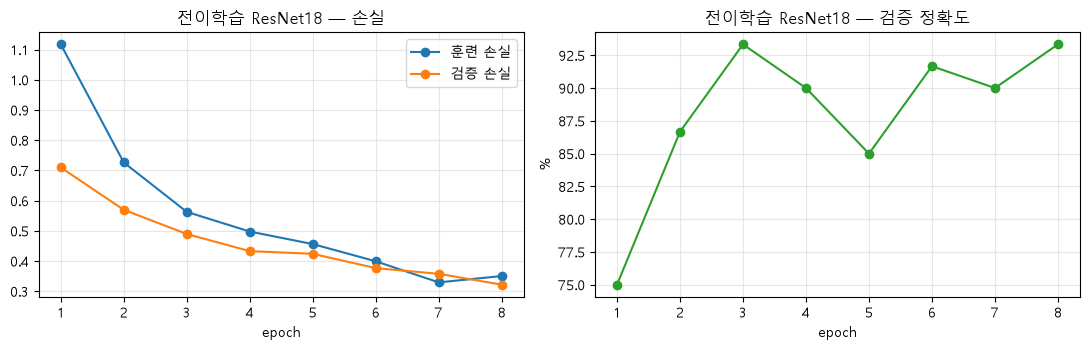

In [8]:
# 셀 7 — 전이학습 모델 학습  (빈칸 없음 — 셀 4 의 fit 을 그대로 다시 쓴다)
tl_hist = fit(resnet, epochs=8, lr=1e-3, save_path="models/resnet_tl.pt")
plot_history(tl_hist, "전이학습 ResNet18")

**기대 출력** (교수 PC CPU 실측 · 학습 59.7초)
```
epoch  1 | 훈련 손실 1.1173 | 검증 손실 0.7098 | 검증 정확도  75.0%  ← 최고, 저장
epoch  2 | 훈련 손실 0.7263 | 검증 손실 0.5696 | 검증 정확도  86.7%  ← 최고, 저장
epoch  3 | 훈련 손실 0.5628 | 검증 손실 0.4896 | 검증 정확도  93.3%  ← 최고, 저장
epoch  4 | 훈련 손실 0.4977 | 검증 손실 0.4329 | 검증 정확도  90.0%
epoch  5 | 훈련 손실 0.4562 | 검증 손실 0.4240 | 검증 정확도  85.0%
epoch  6 | 훈련 손실 0.3993 | 검증 손실 0.3767 | 검증 정확도  91.7%
epoch  7 | 훈련 손실 0.3294 | 검증 손실 0.3578 | 검증 정확도  90.0%
epoch  8 | 훈련 손실 0.3504 | 검증 손실 0.3217 | 검증 정확도  93.3%

최고 검증 정확도 93.3%  |  학습 시간 59.7초  |  저장 : models/resnet_tl.pt
```

> **관찰 ★★**: **첫 epoch 부터 75.0%** — 내 CNN 이 15 epoch 동안 겨우 도달한 최고(76.7%)와 거의 같습니다. 3 epoch 만에 **93.3%** 에 도달했고, 훈련·검증 손실이 나란히 내려갑니다(과적합 신호 없음). 학습한 파라미터는 1,539개로 내 CNN(94,083개)의 약 1.6% 뿐입니다.

---

## 5단계 — 평가: 혼동행렬과 비교표

정확도 한 숫자만으로는 **무엇을 무엇으로 헷갈렸는지** 알 수 없습니다.
**혼동행렬**은 *"정답이 A 인 사진을 모델이 무엇이라고 했나"* 를 표로 보여 줍니다.

```
                 모델의 예측 →
               비행기  자동차  고양이
  정답 비행기  [  ●      .      .  ]     ← 대각선 = 맞힌 것
       자동차  [  .      ●      .  ]     ← 대각선 밖 = 헷갈린 것
       고양이  [  .      .      ●  ]
```

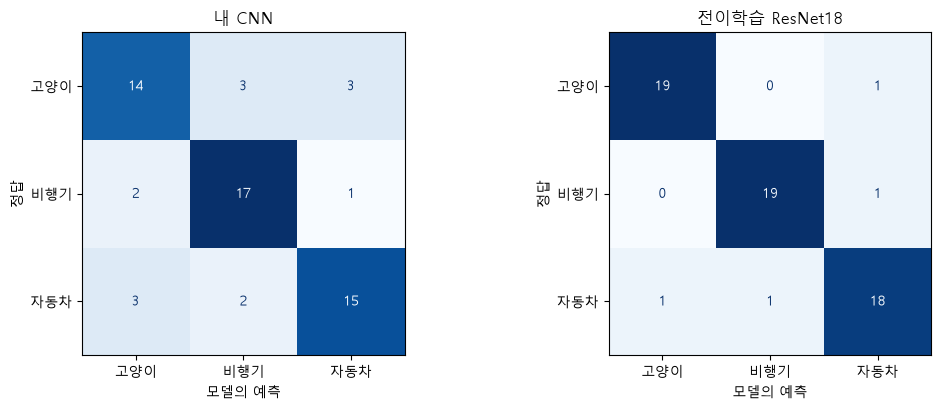

[전이학습 ResNet18 — 클래스별 성적]
              precision    recall  f1-score   support

         고양이      0.950     0.950     0.950        20
         비행기      0.950     0.950     0.950        20
         자동차      0.900     0.900     0.900        20

    accuracy                          0.933        60
   macro avg      0.933     0.933     0.933        60
weighted avg      0.933     0.933     0.933        60



In [9]:
# 셀 8 — 가장 좋았던 모델 불러와 혼동행렬 그리기
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# 빈칸 ⑩ (1줄) — 힌트 : 셀 7 에서 저장한 최고 가중치를 다시 넣는다.
#                      resnet.load_state_dict(torch.load("models/resnet_tl.pt"))
resnet.load_state_dict(torch.load("models/resnet_tl.pt"))
cnn.load_state_dict(torch.load("models/my_cnn.pt"))          # 내 CNN 도 최고 시점으로

@torch.no_grad()
def predict_all(model):
    model.eval(); ys, ps = [], []
    for xb, yb in val_loader:
        ps += model(xb.to(device)).argmax(1).cpu().tolist(); ys += yb.tolist()
    return ys, ps

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for a, (name, m) in zip(ax, [("내 CNN", cnn), ("전이학습 ResNet18", resnet)]):
    ys, ps = predict_all(m)
    ConfusionMatrixDisplay(confusion_matrix(ys, ps), display_labels=CLASSES).plot(ax=a, cmap="Blues", colorbar=False)
    a.set_title(name); a.set_xlabel("모델의 예측"); a.set_ylabel("정답")
plt.tight_layout(); plt.savefig("results/confusion_matrix.png", dpi=120); plt.show()

ys, ps = predict_all(resnet)
print("[전이학습 ResNet18 — 클래스별 성적]")
print(classification_report(ys, ps, target_names=CLASSES, digits=3, zero_division=0))

**기대 출력**
```
[전이학습 ResNet18 — 클래스별 성적]
              precision    recall  f1-score   support

         고양이      0.950     0.950     0.950        20
         비행기      0.950     0.950     0.950        20
         자동차      0.900     0.900     0.900        20

    accuracy                          0.933        60
   macro avg      0.933     0.933     0.933        60
weighted avg      0.933     0.933     0.933        60
```

> **읽는 법**
> - **precision(정밀도)** : 모델이 "고양이"라고 한 것 중 **진짜 고양이**의 비율 — *헛짚지 않았나*
> - **recall(재현율)** : 진짜 고양이 중 모델이 **찾아낸** 비율 — *놓치지 않았나*
> - **f1-score** : 두 값의 균형 점수. 둘 다 높아야 높게 나옵니다.

> **관찰 ★**: 내 CNN 은 고양이 20장 중 6장을 비행기·자동차로 헷갈렸지만(14/20), 전이학습은 클래스마다 1~2장만 틀렸습니다(고양이 19/20 · 비행기 19/20 · 자동차 18/20). 전이학습에서 가장 약한 클래스는 자동차(f1 0.900)입니다.

In [10]:
# 셀 9 — 비교표 만들고 저장  (빈칸 없음)
rows = [
    ("내 CNN (처음부터)", cnn_hist, sum(p.numel() for p in cnn.parameters() if p.requires_grad)),
    ("전이학습 (백본 고정)", tl_hist, trainable),
]
for name, h, n in rows:
    print(f"[{name}]")
    print(f"   학습 파라미터     {n:>12,}개")
    print(f"   최고 검증 정확도  {h['best_acc']*100:>12.1f}%")
    print(f"   학습 시간         {h['time']:>12.1f}초  ({len(h['val_acc'])} epoch)")

result = {name: {"학습파라미터": n, "최고검증정확도": round(h["best_acc"], 4), "학습시간초": round(h["time"], 1)}
          for name, h, n in rows}
result["클래스"] = CLASSES
with open("results/result.json", "w", encoding="utf-8") as f:
    json.dump(result, f, ensure_ascii=False, indent=2)
print("\n저장 : results/result.json  ← 과제 보고서에 이 표를 옮겨 적습니다")

[내 CNN (처음부터)]
   학습 파라미터           94,083개
   최고 검증 정확도          76.7%
   학습 시간                130.8초  (15 epoch)
[전이학습 (백본 고정)]
   학습 파라미터            1,539개
   최고 검증 정확도          93.3%
   학습 시간                 59.7초  (8 epoch)

저장 : results/result.json  ← 과제 보고서에 이 표를 옮겨 적습니다


**기대 출력**
```
[내 CNN (처음부터)]
   학습 파라미터           94,083개
   최고 검증 정확도          76.7%
   학습 시간                130.8초  (15 epoch)
[전이학습 (백본 고정)]
   학습 파라미터            1,539개
   최고 검증 정확도          93.3%
   학습 시간                 59.7초  (8 epoch)

저장 : results/result.json  ← 과제 보고서에 이 표를 옮겨 적습니다
```

> **핵심 ★★**: **학습하는 파라미터는 훨씬 적은데 정확도는 더 높습니다.**
> 데이터가 적을 때는 **처음부터 만드는 것보다 잘 학습된 모델을 빌려 쓰는 것**이 낫습니다.
> 2교시 판서의 *"보는 눈을 빌린다"* 가 숫자로 확인됩니다.

> **학습 시간에 대하여**: ResNet18 은 내 CNN 보다 훨씬 큰 모델인데도 시간이 덜 걸렸습니다.
> 고정한 백본은 **기울기를 계산하지 않기** 때문입니다(역전파는 새 머리에서만). 그리고 **더 적은 epoch 으로 더 높은 정확도**에 도달합니다.
> 시간은 장치(GPU/CPU)에 따라 크게 다르니, 비교할 때는 **같은 PC 에서 잰 값**끼리 비교하세요.

---

## 6단계 — 내 사진 한 장 예측해 보기

인터넷이나 휴대폰에서 **학습에 쓰지 않은 사진** 한 장을 노트북과 같은 폴더에 넣고,
아래 `MY_PHOTO` 에 파일 이름을 적어 실행합니다. 비워 두면 검증 사진 하나로 시험합니다.

사진 : mydata_sample\val\고양이\060.png


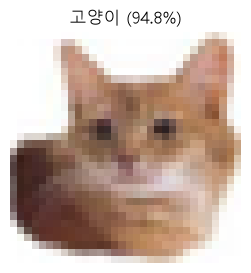

  고양이       94.8%
  비행기        3.1%
  자동차        2.2%


In [11]:
# 셀 10 — 사진 한 장 예측  (빈칸 없음 — 파일 이름만 바꿔 보세요)
from PIL import Image

MY_PHOTO = ""                                    # 예) "my_cat.jpg"

@torch.no_grad()
def predict_one(model, path):
    img = Image.open(path).convert("RGB")
    x = val_tf(img).unsqueeze(0).to(device)       # 검증과 같은 전처리 + 배치 차원 추가
    model.eval()
    prob = torch.softmax(model(x), dim=1)[0].cpu()
    plt.figure(figsize=(3, 3)); plt.imshow(img); plt.axis("off")
    plt.title(f"{CLASSES[prob.argmax()]} ({prob.max()*100:.1f}%)"); plt.show()
    for c, p in sorted(zip(CLASSES, prob.tolist()), key=lambda t: -t[1]):
        print(f"  {c:<8} {p*100:5.1f}%")

path = MY_PHOTO or val_set.samples[0][0]
print("사진 :", os.path.normpath(path))
predict_one(resnet, path)

**기대 출력** (빈칸으로 두었을 때)
```
사진 : mydata_sample\val\고양이\060.png
  고양이       94.8%
  비행기        3.1%
  자동차        2.2%
```

> **해 볼 것**: 학습한 클래스에 **없는** 사진(예: 꽃)을 넣어 보세요. 모델은 그래도 셋 중 하나라고 답합니다.
> 분류 모델은 **아는 보기 안에서만** 고른다는 점을 기억해 두세요.

---

## 도전 (선택) — 전체 미세조정

백본까지 **전부 풀어서** 아주 작은 학습률(`1e-4`)로 조금 더 학습합니다.
내 데이터에 더 잘 맞출 수 있지만, 계산이 많고 데이터가 적으면 과적합이 생기기 쉽습니다.

> ⚠️ **GPU 에서만 실행을 권장합니다.** CPU 에서는 시간이 오래 걸립니다.

In [12]:
# 셀 11 — (선택) 전체 미세조정
for p in resnet.parameters():
    p.requires_grad = True                        # 백본까지 전부 학습

ft_hist = fit(resnet, epochs=5, lr=1e-4, save_path="models/resnet_ft.pt")
n_ft = sum(p.numel() for p in resnet.parameters())
print(f"\n전체 미세조정 | 학습 파라미터 {n_ft:,} | 최고 검증 정확도 {ft_hist['best_acc']*100:.1f}%")

epoch  1 | 훈련 손실 0.3080 | 검증 손실 0.1096 | 검증 정확도  98.3%  ← 최고, 저장


epoch  2 | 훈련 손실 0.1430 | 검증 손실 0.1660 | 검증 정확도  93.3%


epoch  3 | 훈련 손실 0.0729 | 검증 손실 0.1089 | 검증 정확도  98.3%


epoch  4 | 훈련 손실 0.1110 | 검증 손실 0.0955 | 검증 정확도  96.7%


epoch  5 | 훈련 손실 0.0571 | 검증 손실 0.1558 | 검증 정확도  93.3%

최고 검증 정확도 98.3%  |  학습 시간 89.3초  |  저장 : models/resnet_ft.pt

전체 미세조정 | 학습 파라미터 11,178,051 | 최고 검증 정확도 98.3%


**기대 출력** (교수 PC CPU 실측 · 학습 89.3초)
```
epoch  1 | 훈련 손실 0.3080 | 검증 손실 0.1096 | 검증 정확도  98.3%  ← 최고, 저장
epoch  2 | 훈련 손실 0.1430 | 검증 손실 0.1660 | 검증 정확도  93.3%
epoch  3 | 훈련 손실 0.0729 | 검증 손실 0.1089 | 검증 정확도  98.3%
epoch  4 | 훈련 손실 0.1110 | 검증 손실 0.0955 | 검증 정확도  96.7%
epoch  5 | 훈련 손실 0.0571 | 검증 손실 0.1558 | 검증 정확도  93.3%

최고 검증 정확도 98.3%  |  학습 시간 89.3초  |  저장 : models/resnet_ft.pt

전체 미세조정 | 학습 파라미터 11,178,051 | 최고 검증 정확도 98.3%
```

> **생각해 볼 것**: 정확도가 올랐다면 그 대가로 무엇을 더 썼나요? (학습 파라미터 수 · 시간)
> 과제의 마지막 질문 *"나라면 어느 방식을 쓰겠는가"* 에 이 비교를 근거로 쓸 수 있습니다.

---

## 과제 — 내 이미지 분류 미니 프로젝트 보고서

| 제출물 | 내용 |
|---|---|
| ① 노트북 | 이 노트북을 **`14_image_project.ipynb`** 로 저장 (빈칸 10곳 완성 · 실행 결과 포함) |
| ② 비교표 | 셀 9 의 표 (내 CNN vs 전이학습) — 도전을 했다면 전체 미세조정 행 추가 |
| ③ 학습 곡선 해석 | 내 CNN 곡선에서 **과적합 신호가 보였는가?** 근거 2줄 |
| ④ 혼동행렬 해석 | **가장 많이 헷갈린 클래스 쌍**과 그 이유 추측 2줄 |
| ⑤ 내 사진 예측 | 학습에 쓰지 않은 사진 **3장**의 예측 결과 (맞은 것·틀린 것 모두 괜찮음) |
| ⑥ 결론 | **"내 데이터라면 어느 방식을 쓰겠는가"** 와 그 이유 **5줄** ★ |

> **가장 중요한 것은 ⑥ 입니다.** 숫자를 근거로 *"이러이러하므로 나는 이 방식을 고르겠다"* 를 쓰세요.

### 체크리스트

- [ ] 증강을 훈련 데이터에만 넣었다
- [ ] Conv → BN → ReLU → Pool 블록으로 CNN 을 만들고 shape 을 검산했다
- [ ] 학습 루프 5단계를 직접 썼다
- [ ] 검증 정확도가 가장 좋았던 순간을 `state_dict` 로 저장했다
- [ ] 훈련/검증 곡선을 보고 과적합 여부를 말할 수 있다
- [ ] ResNet18 의 백본을 고정하고 머리(`fc`)를 바꿔 전이학습을 했다
- [ ] 혼동행렬을 읽고 헷갈린 클래스를 찾았다
- [ ] 두 방식의 비교표를 만들었다